# Name: // Seyedeh Sharareh Mirzargar

In [1]:
%matplotlib inline
import torch
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

from tqdm.notebook import tqdm
from IPython.display import clear_output

#my libraries
from torch.utils.data import DataLoader
from torchvision.transforms import Compose, ToTensor, Normalize
import seaborn as sns
from torch.utils.data import Dataset
import random
from torchvision.datasets import MNIST
from copy import deepcopy
# Define which device to use for computations
# If you have gpu, use 'cuda'
device = torch.device('cuda')

Mounting google drive to save the plots and models

# ***Notice: I save the trained model in a ".pth" file and then read it again when I want to test it. Therefore, mind changing the root directory to the correct one. Default value is: './' ***

In [2]:
#Please uncomment if you would like to save the files to your google drive. Please not an authentication is needed
# from google.colab import drive
# drive.mount('/content/drive')
# root = '/content/drive/MyDrive/Google colab/ATML21/Ex1/'

root = './'

# Assignment 1 ATML 2021

## Task 1. Prepare data for training and model selection

PyTorch torchvision module provides you with some predesigned datasets. Like the MNIST dataset, that we are going to use (https://pytorch.org/vision/0.8/_modules/torchvision/datasets/mnist.html#MNIST). Let us build a simple MNIST dataset and visualise some samples.

I have integrated the "dataset.py" file with the Jupyternote book. This is because I was running the code on google colab and each time it disconnects from the server, all the auxiliary files that were uploaded to the server (which is very uncomfortable)

In [3]:
class MnistPairs(Dataset):
    """Dataset with Mnist pairs."""

    def __init__(self, root, train, download, transform=None, order='right', return_original_labels=False):
        """
        Args:
            root (string): Directory to store the downloaded MNIST dataset.
            train (bool): If True, use the training part of the MNIST dataset.
            download(bool): If True, will download the dataset, if it is not in the root folder.
            transform (callable, optional): Optional transform to be applied
                on a sample.
            order (str): Indicates which ordering of digits to use, ['right', 'left'].
            return_original_labels (bool): Indicates if it is needed to return the original MNIST labels.
        """
        
        assert order in ['right', 'left'], "Got unexpected order argument. Expected one of ['right', 'left']"
        self.order = order
        
        self.return_original_labels = return_original_labels
        
        self.mnist_dataset = torchvision.datasets.MNIST(
            root=root,
            train=train,
            download=download,
            transform=transform)

    def __len__(self):
        # MnistPairs should be half the size of the MNIST dataset
        return len(self.mnist_dataset) // 2

    def __getitem__(self, idx):
        # You need to implement this method in such a way
        # that the ith element of the MnistPairs class
        # is a pair of subsequent MNIST dataset samples.
        # Make sure that you process the order in a right way.
        # That is if MNIST is [a, b, c, d], then MnistPairs
        # with the 'right' order are [[a, b], [c, d]],
        # and [[b, a], [d, c]] for the 'left' order.
        # The label is mod 10 sum of the MNIST labels.
        
        first_image = None
        first_image_idx = None
        first_label = None
        first_label_idx = None
        second_image = None
        second_image_idx = None
        second_label = None
        second_label_idx = None
        label = None
        
        #########################
        #     Your code         #
        #########################
        first_image_idx, first_label_idx = self.mnist_dataset[idx*2]
        second_image_idx, second_label_idx = self.mnist_dataset[idx*2+1]
        if(self.order == 'right'):
          #[5,0]
          if(first_label_idx > second_label_idx):
            first_label = first_label_idx
            first_image = first_image_idx
            second_label = second_label_idx
            second_image = second_image_idx
          else:
            first_label = second_label_idx
            first_image = second_image_idx
            second_label = first_label_idx
            second_image = first_image_idx
        else: #left order
          ##[0,5]
          if(first_label_idx < second_label_idx):
            first_label = first_label_idx
            first_image = first_image_idx
            second_label = second_label_idx
            second_image = second_image_idx
          else:
            first_label = second_label_idx
            first_image = second_image_idx
            second_label = first_label_idx
            second_image = first_image_idx

        label = (first_label + second_label) % 10
        pass
        
        #########################
        #     End of your code  #
        #########################
        
        if self.return_original_labels:
            return first_image, second_image, label, first_label, second_label
        
        return first_image, second_image, label

For the needs of this assignment you will have to implement a similar Dataset class which will yield an image pair and a label equal to the mode 10 sum of the labels in the pair. 

### MnistPairs dataset

Implement the __getitem__ method in the dataset.py file. Build training and test sets with the 'right' and 'left' orders of the digits. Split the both training sets into training and validation sets with 90% and 10% of the data respectively. Concatenate the validation sets into one with both 'right' and 'test' orders. The same should be done with the test sets. Visualise some samples from the constructed datasets.

As I have integrated the "dataset.py" with the jupyter notebook, there is no need to import the MnistPairs class

In [4]:
#from dataset import MnistPairs

####Downloading the MNIST dataset and creating the desired datasets

In [5]:
root_dir = '.'
!wget www.di.ens.fr/~lelarge/MNIST.tar.gz
!tar -zxvf MNIST.tar.gz
#transformation to convert images to tensor
transforms = Compose([ToTensor(),
                      Normalize(mean=(0.5,), std=(0.5,))])
#train_dateset
train_dataset_right = MnistPairs(root=root_dir, train=True, download=False, transform= transforms, order='right', return_original_labels=True)
train_dataset_left = MnistPairs(root=root_dir, train=True, download=False, transform= transforms, order='left', return_original_labels=True)
#test dataset
test_dataset_right = MnistPairs(root=root_dir, train=False, download=False, transform= transforms, order='right', return_original_labels=True)
test_dataset_left = MnistPairs(root=root_dir, train=False, download=False, transform= transforms, order='left', return_original_labels=True)


--2021-03-26 10:03:19--  http://www.di.ens.fr/~lelarge/MNIST.tar.gz
Resolving www.di.ens.fr (www.di.ens.fr)... 129.199.99.14
Connecting to www.di.ens.fr (www.di.ens.fr)|129.199.99.14|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.di.ens.fr/~lelarge/MNIST.tar.gz [following]
--2021-03-26 10:03:20--  https://www.di.ens.fr/~lelarge/MNIST.tar.gz
Connecting to www.di.ens.fr (www.di.ens.fr)|129.199.99.14|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [application/x-gzip]
Saving to: ‘MNIST.tar.gz.1’

MNIST.tar.gz.1          [         <=>        ]  33.20M  18.2MB/s    in 1.8s    

2021-03-26 10:03:22 (18.2 MB/s) - ‘MNIST.tar.gz.1’ saved [34813078]

MNIST/
MNIST/raw/
MNIST/raw/train-labels-idx1-ubyte
MNIST/raw/t10k-labels-idx1-ubyte.gz
MNIST/raw/t10k-labels-idx1-ubyte
MNIST/raw/t10k-images-idx3-ubyte.gz
MNIST/raw/train-images-idx3-ubyte
MNIST/raw/train-labels-idx1-ubyte.gz
MNIST/raw/t10k-images-idx3-ubyte
MNIST/raw

####Spliting the datasets

In [6]:
#spliting the dataset
subset_train_right, subset_valid_right = torch.utils.data.random_split(train_dataset_right, [int(len(train_dataset_right)*0.9) , int(len(train_dataset_right)*0.1)])
subset_train_left, subset_valid_left = torch.utils.data.random_split(train_dataset_left, [int(len(train_dataset_left)*0.9) , int(len(train_dataset_left)*0.1)])

####concatinating the datasets


In [7]:
#Concatinating the validation datasets and the test datasets

train_data_sets = [train_dataset_right,train_dataset_left]

validation_data_sets = [subset_valid_right,subset_valid_left]

test_data_sets = [test_dataset_right,test_dataset_left]

train_dataset_concatinated = torch.utils.data.ConcatDataset(train_data_sets) 
validation_dataset = torch.utils.data.ConcatDataset(validation_data_sets)
test_dataset = torch.utils.data.ConcatDataset(test_data_sets)

####Loading data into RAM

In [8]:
class RAMDatasetWrapper(torch.utils.data.Dataset):
    def __init__(self, dataset, transform=None):
        data = []
        for sample in tqdm(dataset):
            data.append(sample)
        self.n = len(dataset)
        self.data = data
        self.transform = transform
        
    def __getitem__(self, ind):
        if self.transform is not None:
            return self.transform(self.data[ind][0]), self.data[ind][1]
        else:
            return self.data[ind]

    def set_transform(self, transform):
        self.transform = transform
    
    def __len__(self):
        return self.n

####Visualizing some samples from the datasets

#####train right

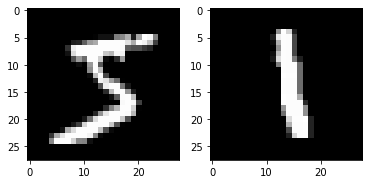

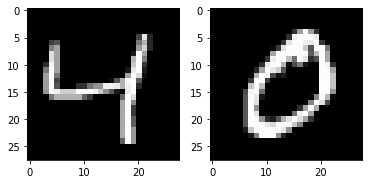

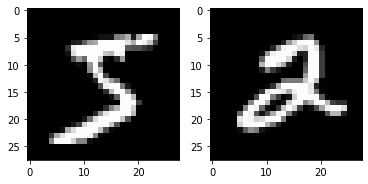

In [9]:
for i in range(3):
  f, axarr = plt.subplots(1,2)
  axarr[0].imshow(train_dataset_right[random.randint(0,3)][0].reshape(28,28), cmap="gray")
  axarr[1].imshow(train_dataset_right[random.randint(0,3)][1].reshape(28,28), cmap="gray")

#####train left

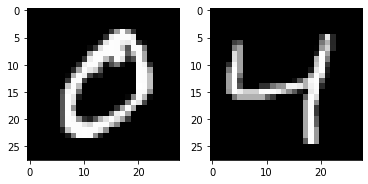

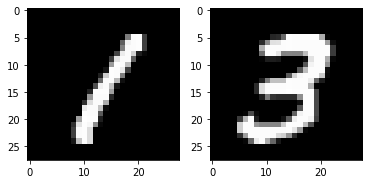

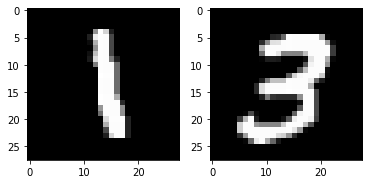

In [10]:
for i in range(3):
  f, axarr = plt.subplots(1,2)
  axarr[0].imshow(train_dataset_left[random.randint(0,3)][0].reshape(28,28), cmap="gray")
  axarr[1].imshow(train_dataset_left[random.randint(0,3)][1].reshape(28,28), cmap="gray")

#####train concatinated

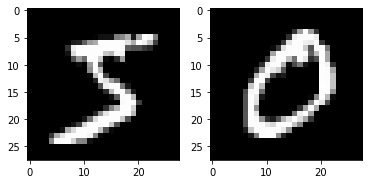

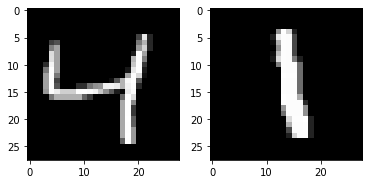

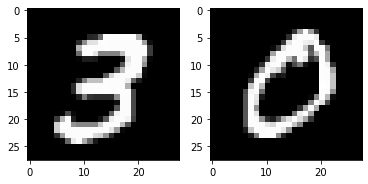

In [11]:
for i in range(3):
  f, axarr = plt.subplots(1,2)
  axarr[0].imshow(train_dataset_concatinated[random.randint(0,3)][0].reshape(28,28), cmap="gray")
  axarr[1].imshow(train_dataset_concatinated[random.randint(0,3)][1].reshape(28,28), cmap="gray")

#####validation

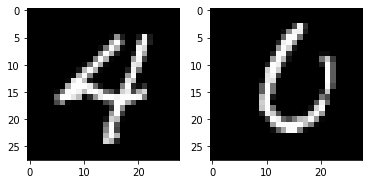

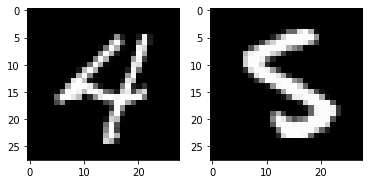

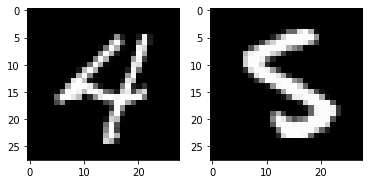

In [12]:
for i in range(3):
  f, axarr = plt.subplots(1,2)
  axarr[0].imshow(validation_dataset[random.randint(0,3)][0].reshape(28,28), cmap="gray")
  axarr[1].imshow(validation_dataset[random.randint(0,3)][1].reshape(28,28), cmap="gray")

#####test


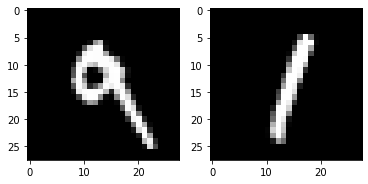

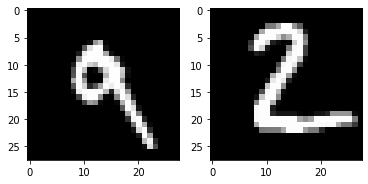

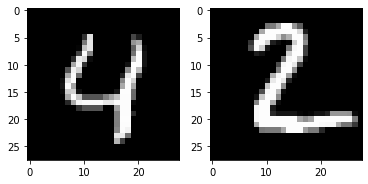

In [13]:
for i in range(3):
  f, axarr = plt.subplots(1,2)
  axarr[0].imshow(test_dataset[random.randint(0,3)][0].reshape(28,28), cmap="gray")
  axarr[1].imshow(test_dataset[random.randint(0,3)][1].reshape(28,28), cmap="gray")

### Label and Pair Distribution

Visualize the distribution of the labels and pairs in the training, validation and testing sets.

####label distribution

In [14]:
def calculate_distribution_of_labels(dataset):
  label_freq = np.zeros(10)
  for data in dataset:
    label_freq[data[2]] = label_freq[data[2]]+1
  
  plt.figure('label_freq')
  plt.xticks(range(0,10))
  plt.plot(label_freq,'ro')
  plt.show()


  pass


#####Train dataset right

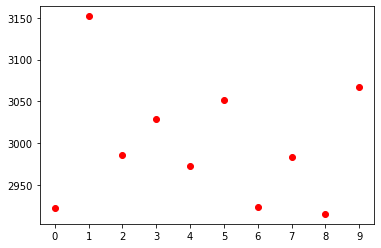

In [15]:
calculate_distribution_of_labels(train_dataset_right)

#####Train dataset left

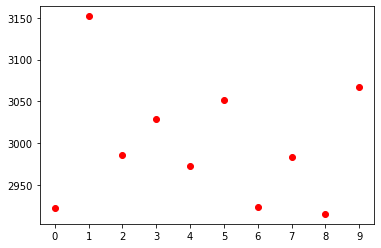

In [16]:
calculate_distribution_of_labels(train_dataset_left)

#####Train dataset concatinated

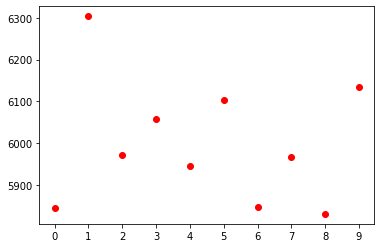

In [17]:
calculate_distribution_of_labels(train_dataset_concatinated)

#####Test dataset

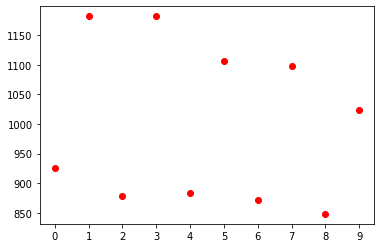

In [18]:
calculate_distribution_of_labels(test_dataset)

#####Validation dataset

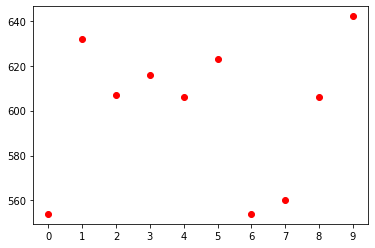

In [19]:
calculate_distribution_of_labels(validation_dataset)

####Pair distribution


In [20]:
def calculate_distribution_of_pairs(dataset):
    label_f = []
    label_s = []
    pair_freq = np.zeros((10,10))
    for data in dataset:
      label_f.append(data[3])
      label_s.append(data[4])
      pair_freq[data[3]][data[4]] = pair_freq[data[3]][data[4]] + 1
    sns.set_theme()
    ax = sns.heatmap(pair_freq)
    pass

#####Train dataset right

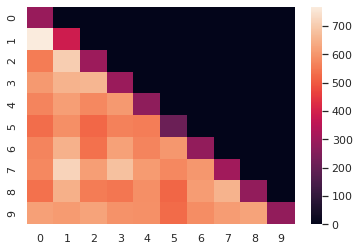

In [21]:
calculate_distribution_of_pairs(train_dataset_right)

#####Train dataset left

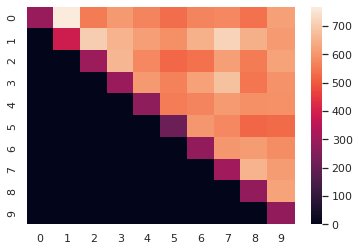

In [22]:
calculate_distribution_of_pairs(train_dataset_left)

#####Train dataset concatinated

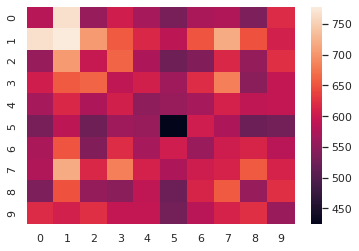

In [23]:
calculate_distribution_of_pairs(train_dataset_concatinated)

#####Test dataset

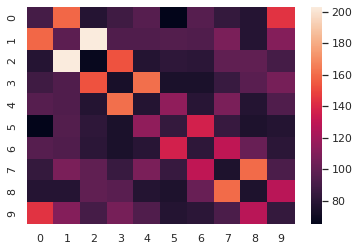

In [24]:
calculate_distribution_of_pairs(test_dataset)

#####Validation dataset

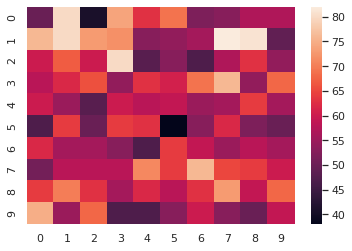

In [25]:
calculate_distribution_of_pairs(validation_dataset)

If the distribution of the labels in the test set differs from the one in the training set, we should expect a different performance of the model on the test set.

>*Answer:* 
As we see above there is an obvious difference in the distribution of both the labels and the distribution of the pairs between the test and train datasets

## Task 2. Design training settings

Having the MnistPairs dataset implemented, we can now nicely wrap in with a DataLoader class for the ease of training.

In [26]:
dataloader_train_right = DataLoader(train_dataset_right, batch_size=32, shuffle=True, num_workers=2)
dataloader_train_left = DataLoader(train_dataset_left, batch_size=32, shuffle=True, num_workers=2)
dataloader_train_concatinated = DataLoader(train_dataset_concatinated, batch_size=32, shuffle=True, num_workers=2)
dataloader_test = DataLoader(test_dataset, batch_size=32, shuffle=True, num_workers=2)
dataloader_validation = DataLoader(validation_dataset, batch_size=32, shuffle=True, num_workers=2)

Define a bunch of models to test, the loss function and the optimizers.

####Model 1


*   Two layers
> * Linear
> * ReLU
> * Linear
* hidden neurons : 128 * 8
*   Cross Entropy loss function
*   SGD optimizer
*   learning rate = 0.05



In [27]:
#fist class
import torch.nn as nn
class ModuleModel1(nn.Module):
    def __init__(self):
        super(ModuleModel1, self).__init__()
        self.main = nn.Sequential(nn.Linear(2 * 28 * 28, 128 * 8),
                                 nn.ReLU(),
                                 nn.Linear(128 * 8, 10))
    
    def forward(self, x, y):
        x = x.view(x.size(0), 28*28)
        y = y.view(y.size(0), 28*28)
        out = torch.cat((x, y), 1)
        out = self.main(out)
        return out

####model 2

*   Three compact layers with Tanh activator
> * Linear
> * Softplus
> * Linear
> * Softplus
> * Linear
* hidden neurons : 128 * 16
*   Cross Entropy loss function
*   SGD optimizer
*   learning rate = 0.05

In [28]:
#second model
import torch.nn as nn
class ModuleModel2(nn.Module):
    def __init__(self):
        super(ModuleModel2, self).__init__()
        self.main = nn.Sequential(nn.Linear(2 * 28 * 28, 128 * 16),
                                 nn.Softplus(),
                                 nn.Linear( 128 * 16, 128 * 16 ),
                                 nn.Softplus(),
                                 nn.Linear( 128 * 16 , 10))
    
    def forward(self, x, y):
        x = x.view(x.size(0), 28*28)
        y = y.view(y.size(0), 28*28)
        out = torch.cat((x, y), 1)
        out = self.main(out)
        return out

####model3

*   Three compact layers
> * Linear
> * ReLU
> * Linear
> * ReLU
> * Linear
* hidden neurons : 128 * 32
*   Cross Entropy loss function
*   SGD optimizer
*   learning rate = 0.05

In [29]:
import torch.nn as nn
#third model
class ModuleModel3(nn.Module):
    def __init__(self):
        super(ModuleModel3, self).__init__()
        self.main = nn.Sequential(nn.Linear(2 * 28 * 28 , 128 * 32),
                                nn.ReLU(),  
                                nn.Linear(128 * 32 , 128 * 32),
                                nn.ReLU(),
                                 nn.Linear(128 * 32 , 10))
    
    def forward(self, x, y):
        x = x.view(x.size(0), 28*28)
        y = y.view(y.size(0), 28*28)
        out = torch.cat((x, y), 1)
        out = self.main(out)
        return out

Arrays of loss functions, optimizers, learning rates, and epoches for the three models

In [30]:
model_cnt = 3
centeral_model_class_arr =  [ModuleModel1, ModuleModel2, ModuleModel3] 
loss_function_list = [nn.CrossEntropyLoss, nn.CrossEntropyLoss, nn.CrossEntropyLoss] 
optimizer_list =     [torch.optim.SGD,     torch.optim.SGD,     torch.optim.SGD    ] 
lr_list =            [0.05,               0.05,                  0.05              ] 
n_epochs_list =      [15,                 15 ,                   15                ]

####Metric, Train, evaluation, test loops

Let us also define the metric we are going to use for the assesment of the model. We will simply use the accuracy of the model.

In [31]:
def accuracy(labels, predictions):
    # Return the accuracy of predictions, i.e. the part of cases
    # where the corresponding prediction matches the label.
    accuracy = 100 * ( np.sum(labels==predictions) / len(labels) )
    return accuracy
    pass

Write the training loop.

In [32]:
def train_model(model, dataloader, optimizer, loss_fn):
    losses = []
    correct_predictions = 0
    model.train()
    for iteration, (images_1, images_2, labels, label_1, label_2) in enumerate(dataloader):

        images_1 = images_1.to(device)
        images_2 = images_2.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        output = model(images_1,images_2) # [batch_size,10] 

        loss = loss_fn(output, labels)

        loss.backward()

        optimizer.step()

        losses.append(loss.item())
        predicted_labels = output.argmax(dim=1)
        correct_predictions += (predicted_labels == labels).sum().item()

        if iteration % 100 == 0:
          print('Training iteration {}: loss {:.4f}:'.format(iteration, loss.item()))
    accuracy = 100.0 * correct_predictions / len(dataloader.dataset)
    mean_loss = np.array(losses).mean()
    return mean_loss, accuracy
    pass

Write the evaluation code.

In [33]:
def evaluate_model(model, dataloader,loss_fn):
  
    model.eval()
    losses = []
    correct_predictions = 0
    predicted_label_list = []

    with torch.no_grad():

        for images_1, images_2, labels, labeles_1, labeles_2 in dataloader:

            images_1 = images_1.to(device)
            images_2 = images_2.to(device)
            labels = labels.to(device)
            # Run predictions
            output = model(images_1,images_2)
            # Compute loss
            loss = loss_fn(output, labels)
            # Save metrics
            predicted_label = output.argmax(dim=1) # find the index with largest value
            predicted_label_list.append(predicted_label)
            correct_predictions += (predicted_label == labels).sum().item()
            losses.append(loss.item())
            
    ## Store and print average test loss and accuracy
    mean_loss =  np.array(losses).mean()
    accuracy = 100* (correct_predictions / len(dataloader.dataset))
    print('Evaluation average loss: {:.4f}, accuracy: {:.3f}'.format(mean_loss, accuracy))
    return mean_loss, accuracy, predicted_label_list
    pass

Write the test code

In [34]:
def test_model(model, dataloader):
  losses = []
  correct_predictions = 0
 
  success_smpl_cnt = 0
  failure_smpl_cnt = 0
  success_samples = []
  failure_samples = []
  incorrect_label = []
  accuracy_pairs = np.zeros((10,10))
  accuracy_list = np.zeros((10,10))
  pair_cnt = np.zeros((10,10))
  indx = 0
  
  with torch.no_grad():
        
        for images_1, images_2, labels, labeles_1, labeles_2 in dataloader:

            images_1 = images_1.to(device)
            images_2 = images_2.to(device)
            labels = labels.to(device)

            output = model(images_1,images_2)

            predicted_label = output.argmax(dim=1) 
            correct_predictions += (predicted_label == labels).sum().item()
            
              
            
            for l1 , l2 , l , p_l , img1 , img2 in zip(labeles_1 , labeles_2 , labels , predicted_label , images_1 , images_2):
              pair_cnt [l1.item()][l2.item()] += 1
              if(p_l.item() == l.item()):
                accuracy_pairs[l1.item() , l2.item()] += 1
                if(success_smpl_cnt < 10): 
                  success_samples.append((img1,img2))
                  success_smpl_cnt +=1
              else:
                if(failure_smpl_cnt < 10):
                  failure_samples.append((img1,img2))
                  incorrect_label.append(p_l)
                  failure_smpl_cnt +=1
            
  for i in range(10):
    for j in range(10):
      accuracy_list[i,j] = (accuracy_pairs[i,j] / pair_cnt[i,j])*100

  accuracy = 100* (correct_predictions / len(dataloader.dataset))

  print('Test average accuracy: {:.3f}'.format(accuracy))
  return accuracy, success_samples, failure_samples, accuracy_list, incorrect_label
  pass

####Plotting

In [35]:
def plot(n_epochs, losses_1, losses_2, accuracies_1, accuracies_2, plt_title, leg1, leg2, model_name, dir ):
    
    plt.figure()
    plt.title("Loss "+ leg1 +' v.s. '+leg2+' for ' + model_name)
    plt.plot(np.arange(n_epochs), losses_1)
    plt.plot(np.arange(n_epochs), losses_2)
    plt.legend([leg1 + '_loss', leg2 + '_loss'])
    plt.xlabel('epoch')
    plt.ylabel('loss value')
    plt.title(plt_title + ' loss')
    plt.savefig(dir + 'loss_'+ plt_title +'_'+model_name +'_' + str(n_epochs) + '.png')

    plt.figure()
    plt.title("Accuracy "+ leg1 +' v.s. '+leg2+' for ' + model_name)
    plt.plot(np.arange(n_epochs), accuracies_1)
    plt.plot(np.arange(n_epochs), accuracies_2)
    plt.legend([leg1 + '_acc', leg2 + '_acc'])
    plt.xlabel('epoch')
    plt.ylabel('accuracy')
    plt.title(plt_title + ' accuracy')
    #Please uncomment if you would like to save the figure, you just need to have to have the follwing pathes: 1) ./train/right and ./train/concatinated
    #plt.savefig(dir + 'accuracy_'+ plt_title+'_'+model_name +'_' + str(n_epochs) + '.png')
    pass

## Task 3. Train on training 'right' set.
Train the models on training 'right' set and select the best model on the validation set.

In [36]:
model1_right = ModuleModel1()
model1_right = model1_right.to(device)

model2_right = ModuleModel2()
model2_right = model2_right.to(device)

model3_right = ModuleModel3()
model3_right = model3_right.to(device)



model_name_list_right =  ['model 1_right', 'model 2_right', 'model 3_right'] #
model_list_right =       [model1_right   ,  model2_right  ,  model3_right] # 
PATH_list_right = []
best_val_acc_list_right = []

for i in range(model_cnt):
  PATH_list_right.append(root+"Seyedeh_Sharareh_Mirzargar_"+model_name_list_right[i]+".pth") # + "models/right/" + str(i) + "/" + model_name_list_right[i] + ".pth")

In [37]:
RAMDatasetWrapper(dataloader_train_right)
RAMDatasetWrapper(dataloader_validation)

In [38]:
train_accuracies = []
train_mean_losses = []
val_accuracies = []
val_mean_losses = []


for i in range(model_cnt):

  PATH = PATH_list_right[i]
  model_name = model_name_list_right[i]
  print("=========================== "+ model_name + " ===========================")
  model = model_list_right[i]
  loss_fn = loss_function_list[i]()
  lr = lr_list[i]
  optimizer = optimizer_list[i](model.parameters(),lr)

  train_accuracies.append( [] )
  train_mean_losses.append( [] )
  val_accuracies.append( [] )
  val_mean_losses.append( [] )

  ### EARLY STOPPING INITIALIZATION
  best_val_loss = np.inf
  best_val_acc = -np.inf
  best_model = None
  patience = 5 # if no improvement after 5 epochs, stop training
  counter = 0
  ###

  for epoch in range(n_epochs_list[i]):

    print('Epoch {}'.format(epoch+1))
    train_mean_loss, train_accuracy = train_model(model, dataloader_train_right , optimizer, loss_fn) #dataloader_train_right
    train_mean_losses[i].append(train_mean_loss)
    train_accuracies[i].append(train_accuracy)

    val_mean_loss, val_accuracy, predicted_labels = evaluate_model(model, dataloader_validation,loss_fn) #dataloader_validation
    val_accuracies[i].append(val_accuracy)
    val_mean_losses[i].append(val_mean_loss)

    ### EARLY STOPPING CODE
    if val_mean_loss < best_val_loss: # If validation loss improved, save the model and reset the counter
        best_val_loss = val_mean_loss
        best_val_acc = val_accuracy
        best_model = deepcopy(model)
        counter = 0
    else: # If validation loss not improved, increase the counter
        counter += 1
    if counter == patience: # If no improvement for some number of epochs, stop training
        print('No improvement for {} epochs; training stopped.'.format(patience))
        break
    # Copy best model parameters to model
    
  best_val_acc_list_right.append(best_val_acc)
  for param1, param2 in zip(model.parameters(), best_model.parameters()):
      param1.data = param2.data
  torch.save(model.state_dict(), PATH)

=========================== model 1_right ===========================
Epoch 1
Training iteration 0: loss 2.3272:
Training iteration 100: loss 2.0864:
Training iteration 200: loss 2.0854:
Training iteration 300: loss 1.9996:
Training iteration 400: loss 1.7499:
Training iteration 500: loss 1.5034:
Training iteration 600: loss 1.4128:
Training iteration 700: loss 1.3418:
Training iteration 800: loss 1.2608:
Training iteration 900: loss 1.0625:
Evaluation average loss: 3.0873, accuracy: 34.267
Epoch 2
Training iteration 0: loss 0.8971:
Training iteration 100: loss 1.1942:
Training iteration 200: loss 0.7782:
Training iteration 300: loss 1.2824:
Training iteration 400: loss 0.9132:
Training iteration 500: loss 0.8475:
Training iteration 600: loss 0.9112:
Training iteration 700: loss 0.8812:
Training iteration 800: loss 0.5695:
Training iteration 900: loss 0.9262:
Evaluation average loss: 3.3807, accuracy: 41.950
Epoch 3
Training iteration 0: loss 0.3412:
Training iteration 100: loss 0.5258

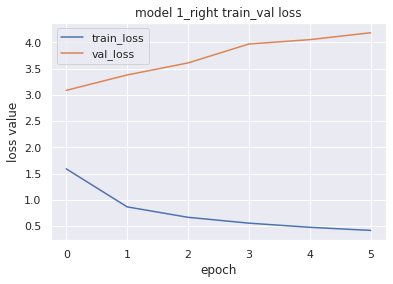

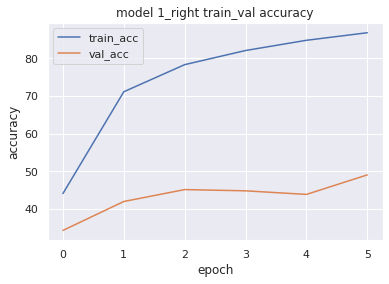

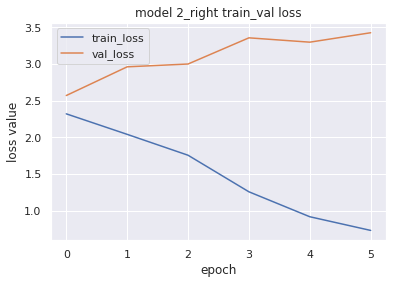

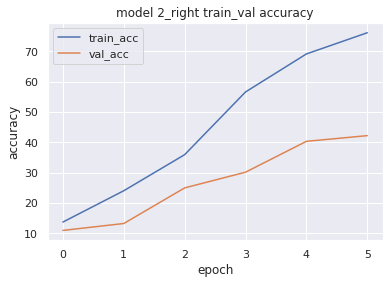

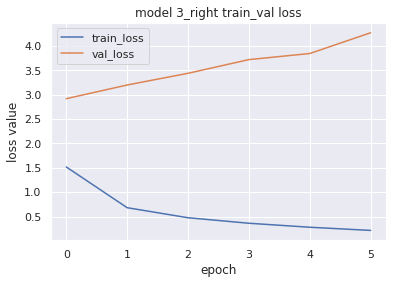

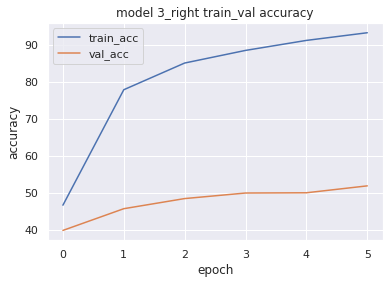

In [39]:
for i in range(model_cnt):
  plot(n_epochs = len(train_mean_losses[i]), losses_1 = train_mean_losses[i], losses_2 = val_mean_losses[i], accuracies_1 = train_accuracies[i], accuracies_2 = val_accuracies[i], plt_title = model_name_list_right[i] + ' train_val',
       leg1 = 'train', leg2 = 'val', model_name = model_name_list_right[i],dir = root )

In [40]:
best_val_acc_right = max(best_val_acc_list_right)
best_model_index_right = best_val_acc_list_right.index(best_val_acc_right)
best_model_name_right = model_name_list_right [best_model_index_right]

print("the accuracy of the best model on the validation set is: " + str(best_val_acc_right))
print("Best model: "+ best_model_name_right)

the accuracy of the best model on the validation set is: 39.88333333333333
Best model: model 3_right


Justify your selection
>*Answer:*

> For all the three models, I have included the early stopping technique so that none of the models overfit due to a long number of epoches. The model one, two, and three stop after 6, 6, and 6 epoches respectively. Model three achieves the best accuracy on the validation set (>39%) and therefore Model three is chosen as the best model in this task. If we consider its architecture, this is a logical result because first of all, model three has more number of layers compared to model one and also it has a higher number of hidden neurons compared to model two and three. In comparison with model two, model three uses ReLU as activator which usually works better than softplus layers in practice.

## Task 4. Train on concatenated training set.

Train the models on concatenated training set and select the best model on the validation set.

In [41]:
model1_concatinated = ModuleModel1()
model1_concatinated = model1_concatinated.to(device)

model2_concatinated = ModuleModel2()
model2_concatinated = model2_concatinated.to(device)

model3_concatinated = ModuleModel3()
model3_concatinated = model3_concatinated.to(device)



model_name_list_concatinated =  ['model 1_concatinated', 'model 2_concatinated', 'model 3_concatinated'] #
model_list_concatinated =       [model1_concatinated,    model2_concatinated,   model3_concatinated] #

PATH_list_concatinated = []
best_val_acc_list_concatinated = []

for i in range(model_cnt):
  PATH_list_concatinated.append(root+"Seyedeh_Sharareh_Mirzargar_"+model_name_list_right[i]+".pth") #+ "models/concatinated/" + str(i) + "/" + model_name_list_concatinated[i] + ".pth")

In [42]:
RAMDatasetWrapper(dataloader_train_concatinated)
RAMDatasetWrapper(dataloader_validation)

In [43]:
train_accuracies = []
train_mean_losses = []
val_accuracies = []
val_mean_losses = []

for i in range(model_cnt):
  
  PATH = PATH_list_concatinated[i]
  model_name = model_name_list_concatinated[i]
  print("===========================" + model_name + "===========================")
  model = model_list_concatinated[i]
  loss_fn = loss_function_list[i]()
  lr = lr_list[i]
  optimizer = optimizer_list[i](model.parameters(),lr)

  train_accuracies.append( [] )
  train_mean_losses.append( [] )
  val_accuracies.append( [] )
  val_mean_losses.append( [] )

  ### EARLY STOPPING INITIALIZATION
  best_val_loss = np.inf
  best_val_acc = -np.inf
  best_model = None
  patience = 5 # if no improvement after 5 epochs, stop training
  counter = 0
    ###

  for epoch in range(n_epochs_list[i]):

    print('Epoch {}'.format(epoch+1))
    train_mean_loss, train_accuracy = train_model(model, dataloader_train_concatinated, optimizer, loss_fn)
    train_mean_losses[i].append(train_mean_loss)
    train_accuracies[i].append(train_accuracy)

    val_mean_loss, val_accuracy, predicted_labels = evaluate_model(model, dataloader_validation, loss_fn)
    val_accuracies[i].append(val_accuracy)
    val_mean_losses[i].append(val_mean_loss)
  ### EARLY STOPPING CODE
    if val_mean_loss < best_val_loss: # If validation loss improved, save the model and reset the counter
        best_val_loss = val_mean_loss
        best_val_acc = val_accuracy
        best_model = deepcopy(model)
        counter = 0
    else: # If validation loss not improved, increase the counter
        counter += 1
    if counter == patience: # If no improvement for some number of epochs, stop training
        print('No improvement for {} epochs; training stopped.'.format(patience))
       
        break
    # Copy best model parameters to model
  best_val_acc_list_concatinated.append(best_val_acc)
  for param1, param2 in zip(model.parameters(), best_model.parameters()):
      param1.data = param2.data
  torch.save(model.state_dict(), PATH)

===========================model 1_concatinated===========================
Epoch 1
Training iteration 0: loss 2.3167:
Training iteration 100: loss 2.2962:
Training iteration 200: loss 2.2751:
Training iteration 300: loss 2.2406:
Training iteration 400: loss 2.2291:
Training iteration 500: loss 2.1171:
Training iteration 600: loss 2.0068:
Training iteration 700: loss 2.1713:
Training iteration 800: loss 2.0716:
Training iteration 900: loss 1.5663:
Training iteration 1000: loss 2.1591:
Training iteration 1100: loss 1.5574:
Training iteration 1200: loss 1.5956:
Training iteration 1300: loss 1.5037:
Training iteration 1400: loss 1.5203:
Training iteration 1500: loss 1.7257:
Training iteration 1600: loss 1.4770:
Training iteration 1700: loss 1.3436:
Training iteration 1800: loss 1.1272:
Evaluation average loss: 1.2538, accuracy: 57.583
Epoch 2
Training iteration 0: loss 1.5840:
Training iteration 100: loss 1.2285:
Training iteration 200: loss 1.4243:
Training iteration 300: loss 1.2284:
Tra

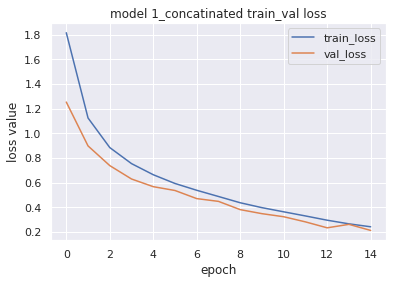

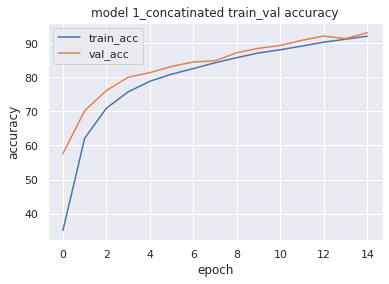

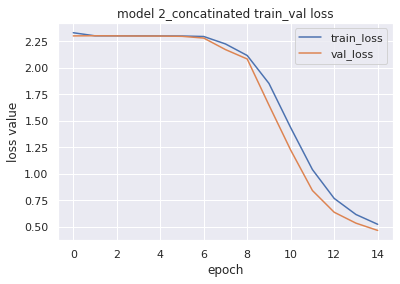

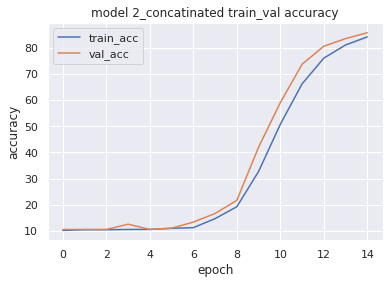

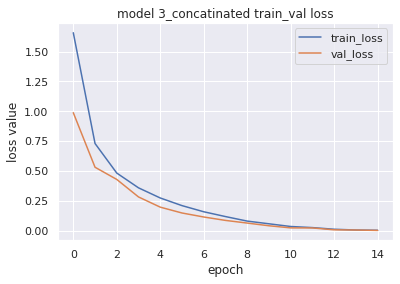

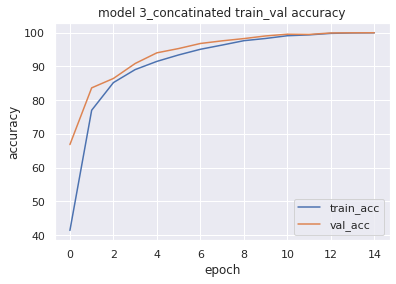

In [44]:
for i in range(model_cnt):
  plot(n_epochs = len(train_mean_losses[i]), losses_1 = train_mean_losses[i], losses_2 = val_mean_losses[i], accuracies_1 = train_accuracies[i], accuracies_2 = val_accuracies[i], plt_title =model_name_list_concatinated[i]+ ' train_val',
       leg1 = 'train', leg2 = 'val', model_name = model_name_list_concatinated[i], dir= root)

In [45]:
best_val_acc_concatinated = max(best_val_acc_list_concatinated)
best_model_index_concatinated = best_val_acc_list_concatinated.index(best_val_acc_concatinated)
best_model_name_concatinated = model_name_list_right [best_model_index_concatinated]
best_model_name_concatinated = model_name_list_concatinated[best_model_index_concatinated]

print("the accuracy of the best model on the validation set is: " + str(best_val_acc_concatinated))
print("Best model: "+ best_model_name_concatinated)

the accuracy of the best model on the validation set is: 100.0
Best model: model 3_concatinated


justify your choice
>*Answer:*

> Similar to the previous task, again Model three outperforms the other models on the validation set with an accuracy of 100. We are using early stopping technique to avoid overfitting and Model one, two, and three stop after 15 epoches. Similar to the pervious part, because first the capacity of model three is higher (three layer instead of two and 4096 hidden neurons instead of 1024 and 2048 ) than the other two models and it uses ReLU instead of SoftPlus, it has a better performance on the validation set. 

##  Task 5. Evaluation

From the previously selected models select the one that shows the best results on the validation set. Let's denote this as the best model. How can you explain the differences in the accuracies of the models trained on different training sets?
> *Answer*
*   Best model:
>> model3 trained on the concatinated dataset from both right and left ordered train datasets
 
*   The differences in the accuracies of models trained on different trainign sets
>> For all the three models, the accuracy of models that are trained on the concatinated training dataset is higher. This is because validation dataset contains samples from both *right*- and *left*-ordered dataset. Models that are trained only using samples from the *right*-order dataset perfom poorly on the validation samples that are *left* ordered. Also, in task 4, the validation loss and training loss are very similar and have a very similar pattern throughout the training. This is a sign of underfitting. Interestingly, while all the models stopped early in task 3 (afte epoch 6 they would have overfitted the training data), in task 4, they all undefit the training data. For example, if one was given the *right*-ordered dataset and wanted to solve the issue of overfitting after epoche 6, one solution was to take all the *left*-ordered samples and add it to their training dataset (which is exactly what task 4 is about). In order to solve this underfitting issue in this task, one can either make the model more complex (unfortunately, in this assignment we can not use  models that have more than three compact layers).




##### Evaluate the model selected in the previous point on the test set and
report your accuracy

In [46]:
best_model_path = root
if( best_val_acc_right > best_val_acc_concatinated):
  best_val_acc = best_val_acc_right
  best_model_path = PATH_list_right[best_model_index_right]
  best_model_name = best_model_name_right
  best_model_index = best_model_index_right
else:
  best_val_acc = best_val_acc_concatinated
  best_model_path = PATH_list_concatinated[best_model_index_concatinated]
  best_model_name = best_model_name_concatinated
  best_model_index = best_model_index_concatinated

print('best model is: ' + best_model_name + "with an accuracy of " + str(best_val_acc))


best model is: model 3_concatinatedwith an accuracy of 100.0


In [47]:
RAMDatasetWrapper(dataloader_test)

Report the accuracy of the best model on the test set.

In [48]:
model = centeral_model_class_arr[best_model_index]()
model.load_state_dict(torch.load(best_model_path))
model = model.to(device)
test_accuracy, success_samples, failure_samples, pairwise_accuracy, incorrect_label = test_model(model, dataloader_test)

Test average accuracy: 91.790


##### Compare this with the validation accuracy.

In [49]:
print("Test average accuracy is {:.4f}, while the best validation accuracy is {:.4f}".format(test_accuracy, best_val_acc))

Test average accuracy is 91.7900, while the best validation accuracy is 100.0000


## Task 6. Visualizations

Visualize some examples of the best model's successful and failure predictions on the test set. Visualize the accuaracy depending on the digit pairs. Why is the model better or worse on some digits? 
> *Answer:*

> First of all, the distribution of pairs in the training set and test set are quite different (for example image pairs with mode {7,3} are fewer in the trainign set and I expect a lower performance on the following pairs: {(0,7) , (7,0) , (1,6) , (6,1) , (2,5) , (5,2) , (3,4) , (4,3)} and {(1,2) , (2,1) , (6,7) , (7,6), (5,8) , (8,5) , (4,9) , (9,4)}). 

>Secondly, some of the pairs are more similar. For example (8,2) is very similar to (3,2) because the digits ***8*** and ***3*** look similar and as the digits are handwritten in some cases, 3 might look very much alike 8. Also, by looking at the failure images, it is obvious that most of them are not well written and it is also hard for a human to detect the label (for example a ***2*** which has been written very similar to an ***a***

>Finally, from the figure that plots accuracy distribution per pairs; we sees that the accuracy for the following pairs is the lowest:  {6,6}, {9,9}, {5,5}, {4,4}, {2,2}. In general, most of the missclassification happens in the diagnal of the plot (for the pairs of same digits). One of the reasons for this missclassification is that if we look at the distribution of the pairs in the train set, its diagnal shows that these pairs have the lowest frequeny among pairs (for example {5,5} is the least frequent pair) and therfore, the model does not perform well for these samples.

>I have also printed that for each pair what is the incorrect label for the failed pairs. For example, in the case of {8,8}, the model has predicted the label to be a ***1***. The following are the pairs whose the mod 10 is 1:
>> {0,1}, {1,0}, {2,9}, {9,2}, {3,8}, {8,3}, {4,7}, {7, 4}, {5,6}, {6,5}

> As you can see one of the pairs is {3,8} and {8,3} and as mentioned earlier, ***8*** and ***3*** are quire similar and if only one of the ***8***s in the pair {8,8} is missclassified as being a ***3*** then the mod 10 would be predicted as being a 1 


Visualize a few samples from your test dataset (both correct and
failure cases) for your final model.

#####Success samples

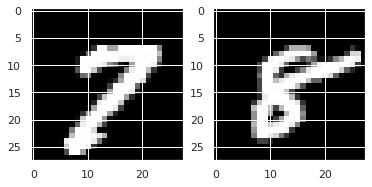

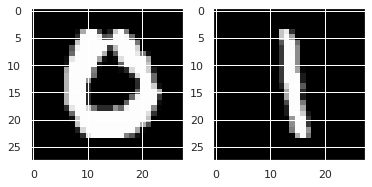

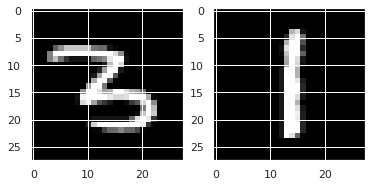

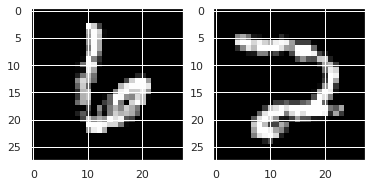

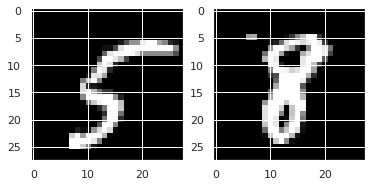

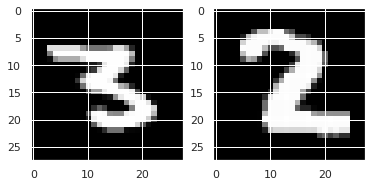

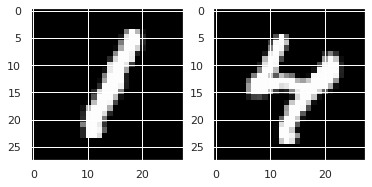

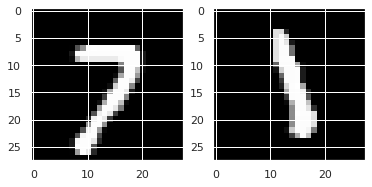

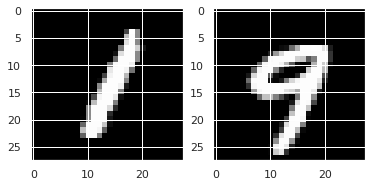

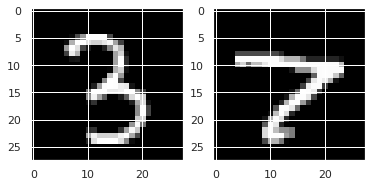

In [50]:
for i in range(10):
  
  f, axarr = plt.subplots(1,2)
  if (device == torch.device('cuda')):
    axarr[0].imshow(success_samples[i][0].cpu().reshape(28,28), cmap="gray")
    axarr[1].imshow(success_samples[i][1].cpu().reshape(28,28), cmap="gray")
  else:
    axarr[0].imshow(success_samples[i][0].reshape(28,28), cmap="gray")
    axarr[1].imshow(success_samples[i][1].reshape(28,28), cmap="gray")


#####Failure samples

miss classified as  1
miss classified as  4
miss classified as  1
miss classified as  9
miss classified as  3
miss classified as  7
miss classified as  5
miss classified as  3
miss classified as  3
miss classified as  7


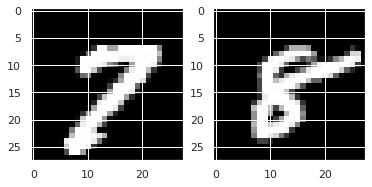

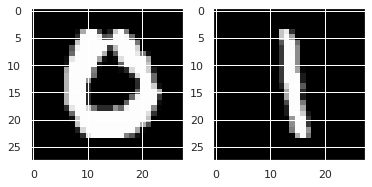

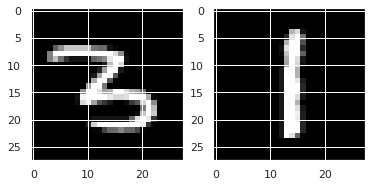

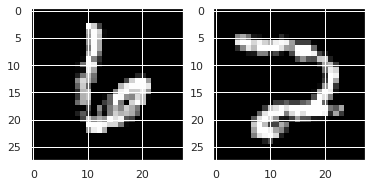

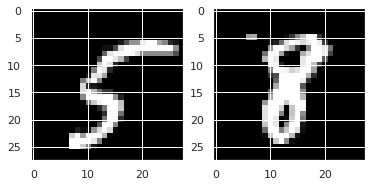

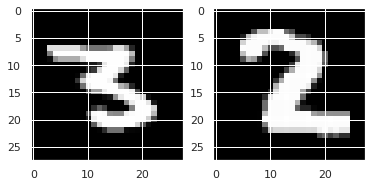

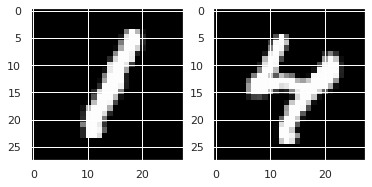

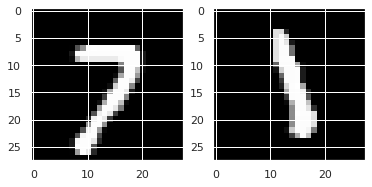

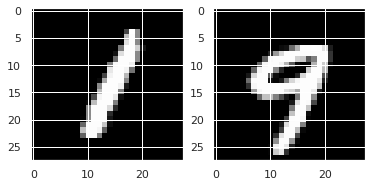

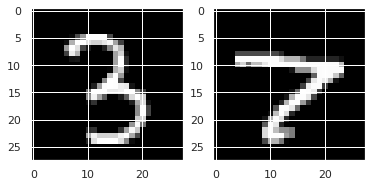

In [51]:
for i in range(10):
  f, axarr = plt.subplots(1,2)
  if (device == torch.device('cuda')):
    axarr[0].imshow(success_samples[i][0].cpu().reshape(28,28), cmap="gray")
    axarr[1].imshow(success_samples[i][1].cpu().reshape(28,28), cmap="gray")
  else:
    axarr[0].imshow(success_samples[i][0].reshape(28,28), cmap="gray")
    axarr[1].imshow(success_samples[i][1].reshape(28,28), cmap="gray")
  print("miss classified as ", incorrect_label[i].item())


##### Accuracy for digit pairs
Show the accuracy of your final model on the test set for each digit
pair.

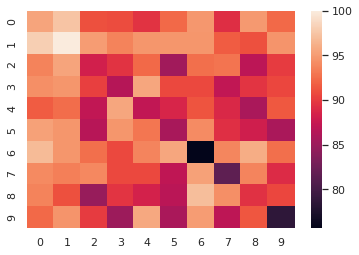

In [52]:

sns.set_theme()
ax = sns.heatmap(pairwise_accuracy)